# JS10 - Lab 3
## Churn Rate Classification with ANN

Model ANN dibangun untuk memprediksi apakah seorang nasabah bank akan **keluar** (*churn*).
Dataset `Churn_Modelling.csv` berisi 10.000 nasabah dengan 14 kolom.

Alur: praproses data (encoding + one-hot + scaling) -> bangun ANN dengan TensorFlow/Keras ->
latih -> evaluasi dengan confusion matrix dan akurasi.

### Step 1 - Import Libraries

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf

# Deterministic training so the reported metrics are reproducible
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


### Step 2 - Load Data

In [2]:
dataset = pd.read_csv('Churn_Modelling.csv')
print("Shape:", dataset.shape)
dataset.head()

Shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
X = dataset.iloc[:, 3:-1].values
y = dataset.iloc[:, -1].values

print("Fitur:", dataset.columns[3:-1].tolist())
print("X shape:", X.shape)
print("Distribusi label:", dict(zip(*np.unique(y, return_counts=True))))
print()
print(X[:3])

Fitur: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
X shape: (10000, 10)
Distribusi label: {np.int64(0): np.int64(7963), np.int64(1): np.int64(2037)}

[[619 'France' 'Female' 42 2 0.0 1 1 1 101348.88]
 [608 'Spain' 'Female' 41 1 83807.86 1 0 1 112542.58]
 [502 'France' 'Female' 42 8 159660.8 3 1 0 113931.57]]


### Step 3 - Encode Categorical Data

Kolom **Gender** berisi dua kategori, sehingga cukup di-*label encode* menjadi 0/1.

In [4]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
X[:, 2] = le.fit_transform(X[:, 2])

print("Gender unik:", dict(zip(le.classes_, le.transform(le.classes_))))
print(X[:3])

Gender unik: {'Female': np.int64(0), 'Male': np.int64(1)}
[[619 'France' 0 42 2 0.0 1 1 1 101348.88]
 [608 'Spain' 0 41 1 83807.86 1 0 1 112542.58]
 [502 'France' 0 42 8 159660.8 3 1 0 113931.57]]


### Step 4 - Encode the "Geography" Column with One Hot Encoder

Kolom **Geography** memiliki tiga kategori (France, Germany, Spain) tanpa urutan, sehingga
di-*one hot encode*. `sparse_output=False` dipakai agar hasilnya berupa array biasa, bukan
matriks sparse.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
ct = ColumnTransformer(transformers=[('encoder', OneHotEncoder(sparse_output=False), [1])], remainder='passthrough')
X = np.array(ct.fit_transform(X))

print("X shape setelah encoding:", X.shape)
print(X[:3])

X shape setelah encoding: (10000, 12)
[[1.0 0.0 0.0 619 0 42 2 0.0 1 1 1 101348.88]
 [0.0 0.0 1.0 608 0 41 1 83807.86 1 0 1 112542.58]
 [1.0 0.0 0.0 502 0 42 8 159660.8 3 1 0 113931.57]]


### Step 5 - Split Data

In [6]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (8000, 12)  Test: (2000, 12)


### Step 6 - Feature Scaling

`StandardScaler` di-*fit* hanya pada data latih, lalu dipakai untuk mentransformasi data uji.
Ini mencegah *data leakage* dari data uji ke proses pelatihan.

In [7]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

print("Rata-rata fitur latih (mendekati 0):", np.round(X_train.mean(axis=0)[:5], 3))

Rata-rata fitur latih (mendekati 0): [-0.  0.  0.  0.  0.]


## Constructing the ANN Model

Arsitektur: **12 input** -> Dense 6 (ReLU) -> Dense 6 (ReLU) -> Dense 1 (sigmoid).

Output tunggal dengan sigmoid karena ini klasifikasi **biner**; nilainya ditafsirkan sebagai
probabilitas nasabah *churn*.

### Step 1 - Initialize the ANN Model

In [8]:
ann = tf.keras.models.Sequential()

### Step 2 - Create the Input Layer and the First Hidden Layer

In [9]:
ann.add(tf.keras.layers.Dense(units=6, activation='relu'))

### Step 3 - Create the Second Hidden Layer

In [10]:
ann.add(tf.keras.layers.Dense(units=6, activation='relu'))

### Step 4 - Create the Output Layer

In [11]:
ann.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

## Training the Model

### Step 1 - Compile the ANN Model

`adam` sebagai optimizer, `binary_crossentropy` sebagai fungsi kerugian (sesuai output sigmoid
tunggal), dan `accuracy` sebagai metrik.

In [12]:
ann.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])

### Step 2 - Fit the Model

In [13]:
history = ann.fit(X_train, y_train, batch_size = 32, epochs = 100, verbose=0)

print("Epoch terakhir - loss:", round(history.history['loss'][-1], 4),
      " accuracy:", round(history.history['accuracy'][-1], 4))

Epoch terakhir - loss: 0.3316  accuracy: 0.8646


### Step 3 - Training Curve

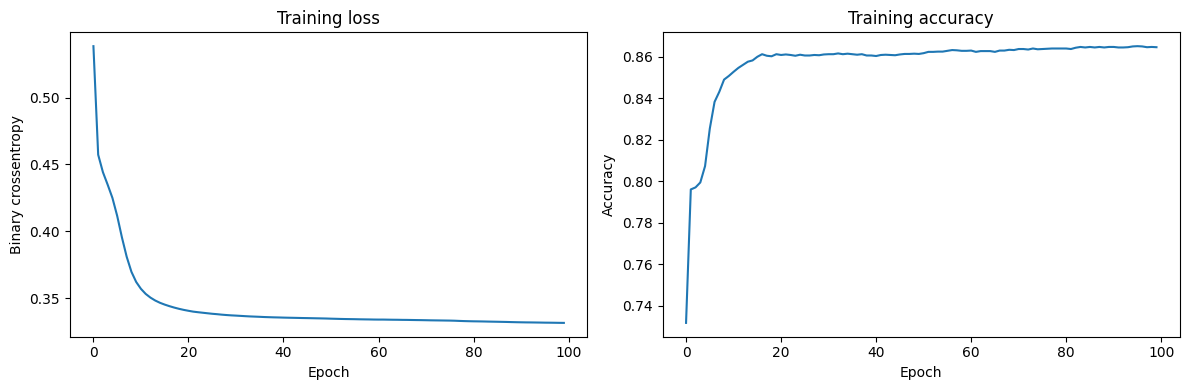

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['loss'])
axes[0].set_title('Training loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Binary crossentropy')

axes[1].plot(history.history['accuracy'])
axes[1].set_title('Training accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
plt.tight_layout()
plt.show()

## Making Predictions

Diberikan data nasabah berikut:

* Geography: France
* Credit Score: 600
* Gender: Male
* Age: 40 years old
* Tenure: 3 years
* Balance: \$ 60000
* Number of Products: 2
* Does this customer have a credit card? Yes
* Is this customer an Active Member: Yes
* Estimated Salary: \$ 50000

Apakah nasabah ini akan *churn*?

### Model the New Data and Make a Prediction

Urutan fitur mengikuti hasil `ColumnTransformer`: 3 kolom one-hot Geography, Gender (0/1),
lalu CreditScore, Age, Tenure, Balance, NumOfProducts, HasCrCard, IsActiveMember, EstimatedSalary.

In [15]:
new_customer = [[1, 0, 0, 600, 1, 40, 3, 60000, 2, 1, 1, 50000]]
proba = ann.predict(sc.transform(new_customer), verbose=0)

print("Probabilitas churn:", round(float(proba[0][0]), 4))
print("Prediksi churn?   :", bool(proba[0][0] > 0.5))

Probabilitas churn: 0.0234
Prediksi churn?   : False


### Predictions with the Testing Data

In [16]:
y_pred = ann.predict(X_test, verbose=0)
y_pred = (y_pred > 0.5)
print(np.concatenate((y_pred.reshape(len(y_pred),1), y_test.reshape(len(y_test),1)),1)[:10])

[[0 0]
 [0 1]
 [0 0]
 [0 0]
 [0 0]
 [1 1]
 [0 0]
 [0 0]
 [0 1]
 [1 1]]

### Evaluate Accuracy and the Confusion Matrix

In [17]:
from sklearn.metrics import confusion_matrix, accuracy_score
cm = confusion_matrix(y_test, y_pred)
print(cm)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

[[1522   73]
 [ 204  201]]
Accuracy: 0.8615


### Classification Report

Akurasi saja menyesatkan pada data yang tidak seimbang. Dataset ini hanya berisi sekitar 20%
nasabah *churn*, sehingga model yang selalu memprediksi "tidak churn" pun akan mendapat akurasi
~80%. Karena itu precision, recall, dan f1-score untuk kelas *churn* perlu diperiksa.

In [18]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=['Not churn', 'Churn']))

              precision    recall  f1-score   support

   Not churn       0.88      0.95      0.92      1595
       Churn       0.73      0.50      0.59       405

    accuracy                           0.86      2000
   macro avg       0.81      0.73      0.75      2000
weighted avg       0.85      0.86      0.85      2000



### Confusion Matrix Visualization

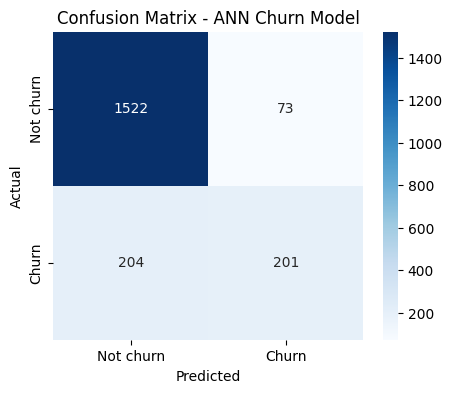

In [19]:
import seaborn as sns

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not churn', 'Churn'],
            yticklabels=['Not churn', 'Churn'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - ANN Churn Model')
plt.show()

### Conclusion

* ANN dengan dua hidden layer (6 neuron, ReLU) mencapai akurasi sekitar **0.86** pada data uji.
  Angka dapat bergeser ~0.005 antar-run karena pelatihan tidak sepenuhnya deterministik.
* Confusion matrix menunjukkan model cukup baik mengenali nasabah yang **tidak** churn, tetapi
  masih melewatkan sekitar separuh nasabah yang benar-benar churn: precision kelas churn ~0.73-0.74
  tetapi recall hanya ~0.50 (sekitar 200 dari 405 nasabah churn tidak terdeteksi).
* Untuk kasus bisnis, recall kelas churn biasanya lebih penting karena biaya kehilangan nasabah
  lebih besar daripada biaya program retensi yang salah sasaran. Penanganannya dapat dilakukan
  dengan *class weight*, penyesuaian *threshold*, atau penambahan data churn.